# 00 · Cálculo de homografía sobre una imagen

**Objetivo:** verificar que, a partir de los keypoints detectados en un frame, se puede calcular una homografía correcta que proyecte las posiciones de la imagen al plano 2D del campo.

**Contexto:** la homografía es la transformación que relaciona los puntos de la imagen (perspectiva de cámara) con sus posiciones reales en el campo (vista cenital). Se calcula con `cv2.findHomography` usando los keypoints detectados (en píxeles) y sus coordenadas reales conocidas (en metros). Es el núcleo del sistema, por lo que se valida primero sobre una sola imagen antes de aplicarlo a vídeo.

**Entrada:** modelo `keypoints_base.pt` y un frame de prueba.

**Salida:** verificación visual de la proyección (imagen → pizarra 2D).

In [1]:
import numpy as np
import cv2
from ultralytics import YOLO
from pathlib import Path

REPO_ROOT = Path("../..").resolve()
KP_MODEL = REPO_ROOT / "models" / "keypoints_base.pt"

# Coordenadas reales de los 24 keypoints en el campo (metros), campo 105x68
# Mismo orden que el modelo
KP_REALES = [
    (0.0, 0.0), (0.0, 68.0), (105.0, 0.0), (105.0, 68.0),
    (16.5, 13.84), (16.5, 54.16), (88.5, 13.84), (88.5, 54.16),
    (5.5, 24.84), (5.5, 43.16), (99.5, 24.84), (99.5, 43.16),
    (11.0, 34.0), (94.0, 34.0), (52.5, 34.0), (52.5, 0.0), (52.5, 68.0),
    (0.0, 13.84), (0.0, 54.16), (105.0, 13.84),
    (0.0, 30.34), (0.0, 37.66), (105.0, 30.34), (105.0, 37.66),
]
KP_REALES = np.array(KP_REALES, dtype=np.float32)

model = YOLO(str(KP_MODEL))
print(f"Modelo cargado. Keypoints: {len(KP_REALES)}")

Modelo cargado. Keypoints: 24


## 1. Detección de keypoints en un frame de prueba

Se elige un frame donde se vea bien una parte del campo y se detectan sus keypoints. Solo se usan los keypoints con confianza suficiente.

In [2]:
# Elegir un frame de prueba (uno donde se vea bien el área)
FRAME = REPO_ROOT / "data" / "bundesliga_keypoints" / "test" / "images"
frames_disponibles = list(FRAME.glob("*.jpg"))
frame_path = frames_disponibles[0]  # puedes cambiar el índice para probar otros

print(f"Frame de prueba: {frame_path.name}")

img = cv2.imread(str(frame_path))
h, w = img.shape[:2]

res = model(str(frame_path), verbose=False, conf=0.25)
r = res[0]

kps_xy = r.keypoints.xy[0].cpu().numpy()      # píxeles
kps_conf = r.keypoints.conf[0].cpu().numpy()

CONF_MIN = 0.5
visibles = kps_conf > CONF_MIN
print(f"Keypoints detectados con confianza > {CONF_MIN}: {visibles.sum()} de 24")

Frame de prueba: A1606b0e6_0_(12)_A1606b0e6_0_(12)_A1606b0e6_0_(12)_frame00456.jpg
Keypoints detectados con confianza > 0.5: 10 de 24


## 2. Cálculo de la homografía

Se emparejan los keypoints detectados (píxeles) con sus coordenadas reales (metros) y se calcula la matriz de homografía con RANSAC, que descarta automáticamente los puntos que no encajan (outliers).

Se necesitan al menos 4 keypoints visibles para calcular la homografía.

In [5]:
# Keypoints poco fiables que excluimos de la homografía (centro y medias)
EXCLUIR = {14, 15, 16}  # centro, media_inf, media_sup

# Emparejar solo keypoints visibles Y fiables
idx_validos = [i for i in range(24) if visibles[i] and i not in EXCLUIR]
src_pts = kps_xy[idx_validos]
dst_pts = KP_REALES[idx_validos]

print(f"Puntos para la homografía (sin centro/medias): {len(src_pts)}")

if len(src_pts) < 4:
    print("ERROR: se necesitan al menos 4 keypoints visibles")
else:
    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 3.0)
    inliers = mask.sum() if mask is not None else 0
    print(f"Homografía calculada")
    print(f"Inliers: {inliers} de {len(src_pts)}")

Puntos para la homografía (sin centro/medias): 8
Homografía calculada
Inliers: 8 de 8


## 3. Verificación: proyectar los keypoints detectados al campo

Para comprobar que la homografía es correcta, se proyectan los propios keypoints detectados al plano del campo y se comparan con sus posiciones reales conocidas. Si la homografía es buena, deberían caer cerca de sus coordenadas reales.

In [6]:
# Proyectar los keypoints detectados usando H
src_h = np.array([src_pts], dtype=np.float32)
proyectados = cv2.perspectiveTransform(src_h, H)[0]

print(f"{'Keypoint':<22} {'Real (m)':<18} {'Proyectado (m)':<20} {'Error (m)':>10}")
print("-" * 72)

KP_NOMBRES = [
    "corner_inf_izq","corner_sup_izq","corner_inf_der","corner_sup_der",
    "area_gr_izq_inf","area_gr_izq_sup","area_gr_der_inf","area_gr_der_sup",
    "area_pq_izq_inf","area_pq_izq_sup","area_pq_der_inf","area_pq_der_sup",
    "penalti_izq","penalti_der","centro","media_inf","media_sup",
    "fondo_izq_inf","fondo_izq_sup","fondo_der_inf",
    "poste_izq_inf","poste_izq_sup","poste_der_inf","poste_der_sup",
]

idx_visibles = np.array(idx_validos)
errores = []
for i, idx in enumerate(idx_visibles):
    real = KP_REALES[idx]
    proy = proyectados[i]
    err = np.linalg.norm(real - proy)
    errores.append(err)
    print(f"{KP_NOMBRES[idx]:<22} ({real[0]:>5.1f},{real[1]:>5.1f})    "
          f"({proy[0]:>6.1f},{proy[1]:>6.1f})     {err:>8.2f}")

print("-" * 72)
print(f"Error medio de reproyección: {np.mean(errores):.2f} metros")

Keypoint               Real (m)           Proyectado (m)        Error (m)
------------------------------------------------------------------------
corner_sup_izq         (  0.0, 68.0)    (  -0.2,  67.6)         0.45
area_gr_izq_inf        ( 16.5, 13.8)    (  15.7,  14.0)         0.79
area_gr_izq_sup        ( 16.5, 54.2)    (  17.1,  54.2)         0.56
area_pq_izq_inf        (  5.5, 24.8)    (   6.2,  24.1)         0.99
area_pq_izq_sup        (  5.5, 43.2)    (   5.1,  43.5)         0.51
fondo_izq_sup          (  0.0, 54.2)    (  -0.3,  54.2)         0.29
poste_izq_inf          (  0.0, 30.3)    (   0.6,  30.0)         0.67
poste_izq_sup          (  0.0, 37.7)    (  -0.1,  38.6)         0.90
------------------------------------------------------------------------
Error medio de reproyección: 0.65 metros


## 4. Dibujar la pizarra 2D del campo

Se dibuja un campo de fútbol a escala (105×68 m) con sus líneas principales: contorno, círculo central, áreas y puntos de penalti. Esta será la vista cenital sobre la que se proyectarán los jugadores.

Figura guardada en: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\outputs\pizarra_campo_vacio.png


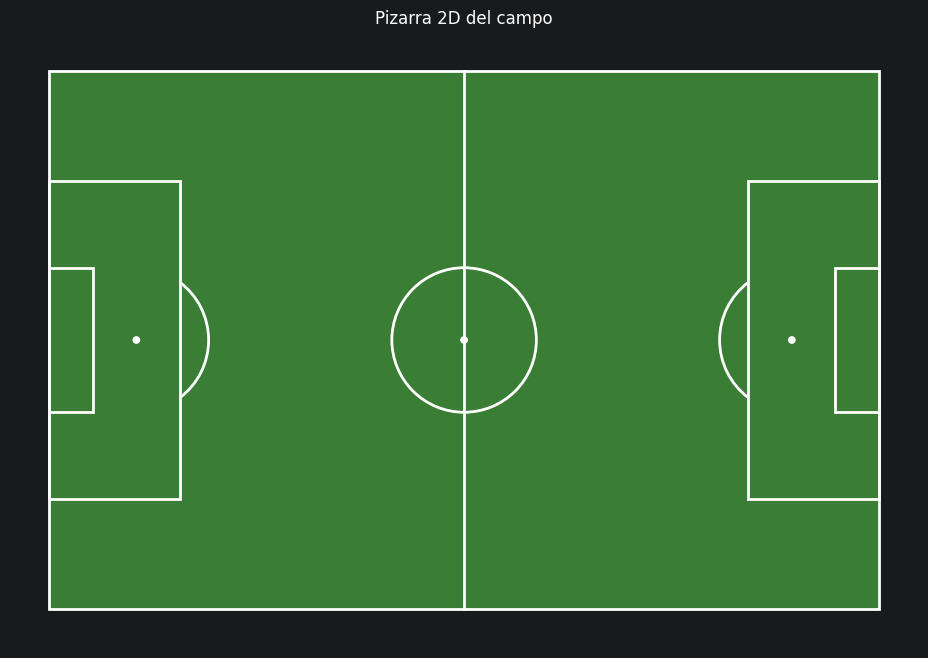

In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Arc

def dibujar_campo(ax):
    """Dibuja un campo de fútbol 2D a escala (105x68 m) sobre el eje dado."""
    # Césped
    ax.add_patch(Rectangle((0, 0), 105, 68, color="#3a7d34", zorder=0))

    lc = "white"
    lw = 2

    # Contorno
    ax.add_patch(Rectangle((0, 0), 105, 68, fill=False, edgecolor=lc, linewidth=lw))
    # Línea media
    ax.plot([52.5, 52.5], [0, 68], color=lc, linewidth=lw)
    # Círculo central
    ax.add_patch(Circle((52.5, 34), 9.15, fill=False, edgecolor=lc, linewidth=lw))
    ax.add_patch(Circle((52.5, 34), 0.4, color=lc))

    # Área grande izquierda
    ax.add_patch(Rectangle((0, 13.84), 16.5, 40.32, fill=False, edgecolor=lc, linewidth=lw))
    # Área pequeña izquierda
    ax.add_patch(Rectangle((0, 24.84), 5.5, 18.32, fill=False, edgecolor=lc, linewidth=lw))
    # Penalti izquierdo
    ax.add_patch(Circle((11, 34), 0.4, color=lc))
    # Arco del área izquierda
    ax.add_patch(Arc((11, 34), 18.3, 18.3, theta1=-53, theta2=53, color=lc, linewidth=lw))

    # Área grande derecha
    ax.add_patch(Rectangle((88.5, 13.84), 16.5, 40.32, fill=False, edgecolor=lc, linewidth=lw))
    # Área pequeña derecha
    ax.add_patch(Rectangle((99.5, 24.84), 5.5, 18.32, fill=False, edgecolor=lc, linewidth=lw))
    # Penalti derecho
    ax.add_patch(Circle((94, 34), 0.4, color=lc))
    # Arco del área derecha
    ax.add_patch(Arc((94, 34), 18.3, 18.3, theta1=127, theta2=233, color=lc, linewidth=lw))

    ax.set_xlim(-5, 110)
    ax.set_ylim(-5, 73)
    ax.set_aspect("equal")
    ax.axis("off")

# Prueba: dibujar el campo vacío
fig, ax = plt.subplots(figsize=(12, 8))
dibujar_campo(ax)
plt.title("Pizarra 2D del campo")
output_fig = REPO_ROOT / "outputs" / "pizarra_campo_vacio.png"
plt.savefig(str(output_fig), dpi=100, bbox_inches="tight")
print(f"Figura guardada en: {output_fig}")
plt.show()

## 5. Detección de jugadores y proyección a la pizarra

Se detectan los jugadores en el frame con el detector v4. Para cada jugador se toma el punto central inferior de su caja (los pies, donde el jugador toca el césped) y se proyecta al campo 2D mediante la homografía. Se proyectan los pies y no el centro porque la homografía corresponde al plano del suelo.

In [8]:
# Cargar el detector v4
DETECTOR = REPO_ROOT / "models" / "best_v4.pt"
detector = YOLO(str(DETECTOR))

# Detectar en el mismo frame de prueba
res_det = detector(str(frame_path), verbose=False, conf=0.3)
rd = res_det[0]

# Clases: 0=ball, 1=player, 2=referee
boxes = rd.boxes.xyxy.cpu().numpy()
clases = rd.boxes.cls.cpu().numpy().astype(int)

print(f"Detecciones totales: {len(boxes)}")
for c in [0, 1, 2]:
    print(f"  Clase {c} ({detector.names[c]}): {(clases==c).sum()}")

Detecciones totales: 25
  Clase 0 (ball): 1
  Clase 1 (player): 21
  Clase 2 (referee): 3


In [9]:
# Para cada detección, calcular el punto de los pies (centro inferior de la caja)
pies_imagen = []
clases_det = []
for (x1, y1, x2, y2), c in zip(boxes, clases):
    px = (x1 + x2) / 2      # centro horizontal
    py = y2                 # parte inferior (pies)
    pies_imagen.append([px, py])
    clases_det.append(c)

pies_imagen = np.array([pies_imagen], dtype=np.float32)

# Proyectar a coordenadas del campo con la homografía
pies_campo = cv2.perspectiveTransform(pies_imagen, H)[0]

print("Posiciones proyectadas (metros):")
for (x, y), c in zip(pies_campo, clases_det):
    print(f"  {detector.names[c]:<10} -> ({x:6.1f}, {y:5.1f})")

Posiciones proyectadas (metros):
  player     -> (  45.2,   8.5)
  player     -> (  31.8,  20.4)
  player     -> (  15.4,  27.3)
  referee    -> (  28.1,  32.9)
  player     -> (  49.7,  27.8)
  player     -> (  61.8,  12.4)
  player     -> (   6.2,  40.1)
  player     -> (  17.4,  36.0)
  player     -> (  23.7,  17.0)
  player     -> (  31.7,  24.8)
  player     -> (  68.4,   8.8)
  player     -> (  15.7,  19.5)
  player     -> (  68.6,  17.2)
  player     -> (  65.3,  34.6)
  player     -> (  51.1,  37.6)
  player     -> (  10.1,  30.7)
  player     -> (  70.7,  17.1)
  player     -> (  13.8,  42.4)
  player     -> (  19.0,  39.4)
  player     -> (  18.1,  12.5)
  player     -> (  44.4,  44.0)
  referee    -> (  63.8, -14.9)
  referee    -> (   4.6,  66.0)
  player     -> (   1.1,  24.0)
  ball       -> (   4.7,  26.0)


Figura guardada en: C:\Users\sgghu\OneDrive\Documents\GitHub\TFG\outputs\pizarra_jugadores.png


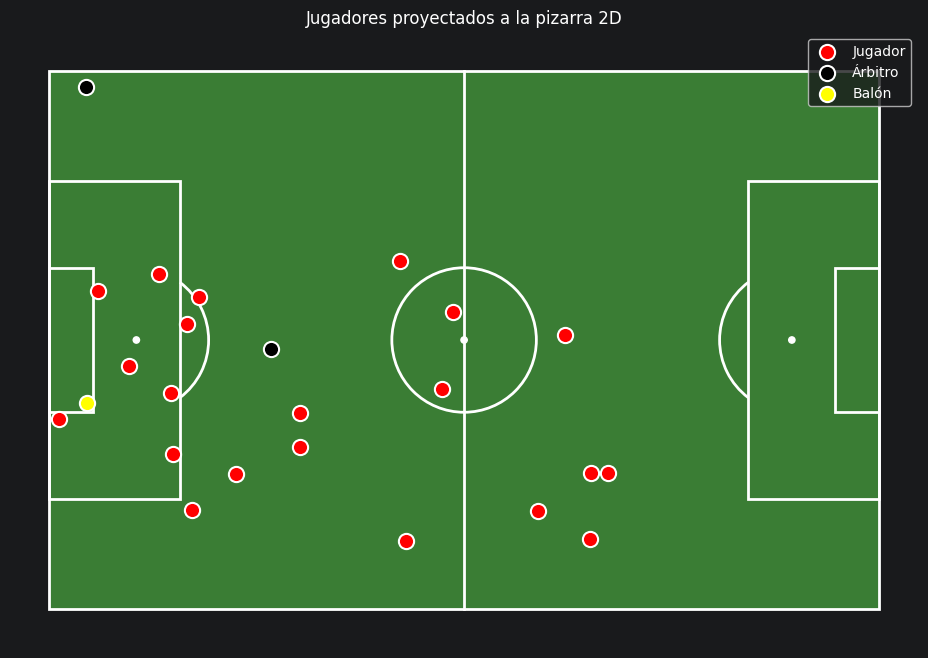

In [10]:
# Dibujar la pizarra con los jugadores proyectados
%matplotlib inline
fig, ax = plt.subplots(figsize=(12, 8))
dibujar_campo(ax)

# Colores por clase
colores = {0: "yellow", 1: "red", 2: "black"}  # balón, jugador, árbitro
etiquetas = {0: "Balón", 1: "Jugador", 2: "Árbitro"}

dibujados = set()
for (x, y), c in zip(pies_campo, clases_det):
    # Solo dibujar si cae dentro de límites razonables del campo (+- margen)
    if -5 <= x <= 110 and -5 <= y <= 73:
        ax.scatter(x, y, c=colores.get(c, "blue"), s=120, edgecolors="white",
                   linewidth=1.5, zorder=5,
                   label=etiquetas.get(c) if c not in dibujados else "")
        dibujados.add(c)

ax.legend(loc="upper right", fontsize=10)
plt.title("Jugadores proyectados a la pizarra 2D")
output_fig = REPO_ROOT / "outputs" / "pizarra_jugadores.png"
plt.savefig(str(output_fig), dpi=100, bbox_inches="tight")
print(f"Figura guardada en: {output_fig}")
plt.show()